# Expanded banana disease model — research preview
**Godson IT**

This extension adds the dataset's **Panama/Fusarium** and **Moko bacterial wilt** labels to the original four classes. Moko is not Xanthomonas wilt. Bunchy top is not trained. The new-class samples are small, so this is not a field-validated diagnostic model.

Original-image source: Mafi, Sifat, Moazzam and Uddin (2023), [Banana Disease Recognition Dataset](https://doi.org/10.17632/79w2n6b4kf.1), CC BY 4.0. Publisher-provided augmented copies were excluded. Training code: `tools/train_expanded_preview.py`; reproducible held-out evaluation: `tools/evaluate_expanded_preview.py`. The original assignment model is preserved.


## 1. Read the saved experiment files

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage
folder = Path("output/expanded_preview")
metrics = json.loads((folder / "evaluation_metrics.json").read_text())
audit = json.loads((folder / "data_audit.json").read_text())
print("Reviewing:", folder)
print("Status:", metrics["status"])


Reviewing: output\expanded_preview
Status: experimental


## 2. Check data provenance and splits
The original assignment split is retained. New originals were deduplicated, grouped by image similarity and split before training. Augmentation is applied only to training images.

In [2]:
print("Original-image source:", audit["source"])
print("License:", audit["license"])
display(pd.DataFrame(audit["classes"]).T)
manifest = pd.read_csv(folder / "split_manifest.csv")
display(pd.crosstab(manifest.class_name, manifest.split))
assert manifest.image.is_unique
print("Unique image paths:", len(manifest))


Original-image source: https://data.mendeley.com/datasets/79w2n6b4kf/1
License: CC BY 4.0


,original_images,similarity_groups
fusarium_wilt,41,41
moko_wilt,55,55


split,test,training,validation
class_name,,,
cordana,25,113,24
fusarium_wilt,7,28,6
healthy,13,63,14
moko_wilt,9,38,8
pestalotiopsis,26,120,26
sigatoka,71,331,71


Unique image paths: 993


## 3. Inspect the actual training history
The existing feature extractor was frozen. Three augmented training views per image were encoded, and the classifier head was trained with class-weighted cross entropy and Adam. Validation loss selected the checkpoint; early stopping used patience six.

In [3]:
history = pd.read_csv(folder / "training_history.csv")
display(history)
print("Selected epoch:", metrics["best_epoch"])


,epoch,training_loss,validation_loss,validation_accuracy
0,1,0.645109,0.310759,0.859060
1,2,0.121720,0.211825,0.946309
2,3,0.079432,0.213865,0.939597
3,4,0.042631,0.181356,0.959732
4,5,0.032299,0.161580,0.959732
5,6,0.023852,0.168844,0.959732
6,7,0.018139,0.143986,0.953020
7,8,0.015357,0.149943,0.953020
8,9,0.011849,0.135060,0.959732
9,10,0.009440,0.148993,0.959732


Selected epoch: 11


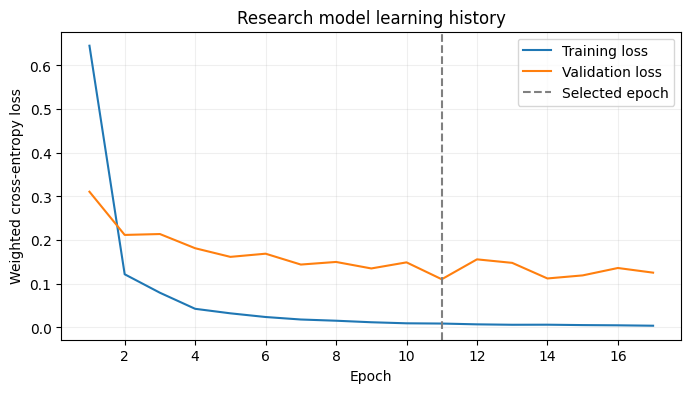

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history.epoch, history.training_loss, label="Training loss")
ax.plot(history.epoch, history.validation_loss, label="Validation loss")
ax.axvline(metrics["best_epoch"], color="grey", linestyle="--", label="Selected epoch")
ax.set(xlabel="Epoch", ylabel="Weighted cross-entropy loss", title="Research model learning history")
ax.legend(); ax.grid(alpha=.2)
plt.show()


## 4. Review held-out results
The accuracy below is for this mixed-source dataset. New-class test supports are just seven Fusarium and nine Moko images; no independent farm generalization is established. Evaluation used the saved center-crop preprocessing.

In [5]:
print(f"Test accuracy: {metrics['test_accuracy']:.2%}")
print(f"Macro F1: {metrics['macro_f1']:.4f}")
print(f"Test loss: {metrics['test_loss']:.4f}")
print("Held-out images:", metrics["test_images"])
report = pd.DataFrame({name: metrics["per_class"][name] for name in metrics["class_names"]}).T
display(report)


Test accuracy: 98.01%
Macro F1: 0.9663
Test loss: 0.0641
Held-out images: 151


,precision,recall,f1-score,support
cordana,1.000000,1.000000,1.000000,25.0
healthy,0.923077,0.923077,0.923077,13.0
pestalotiopsis,0.960000,0.923077,0.941176,26.0
sigatoka,1.000000,1.000000,1.000000,71.0
fusarium_wilt,0.875000,1.000000,0.933333,7.0
moko_wilt,1.000000,1.000000,1.000000,9.0


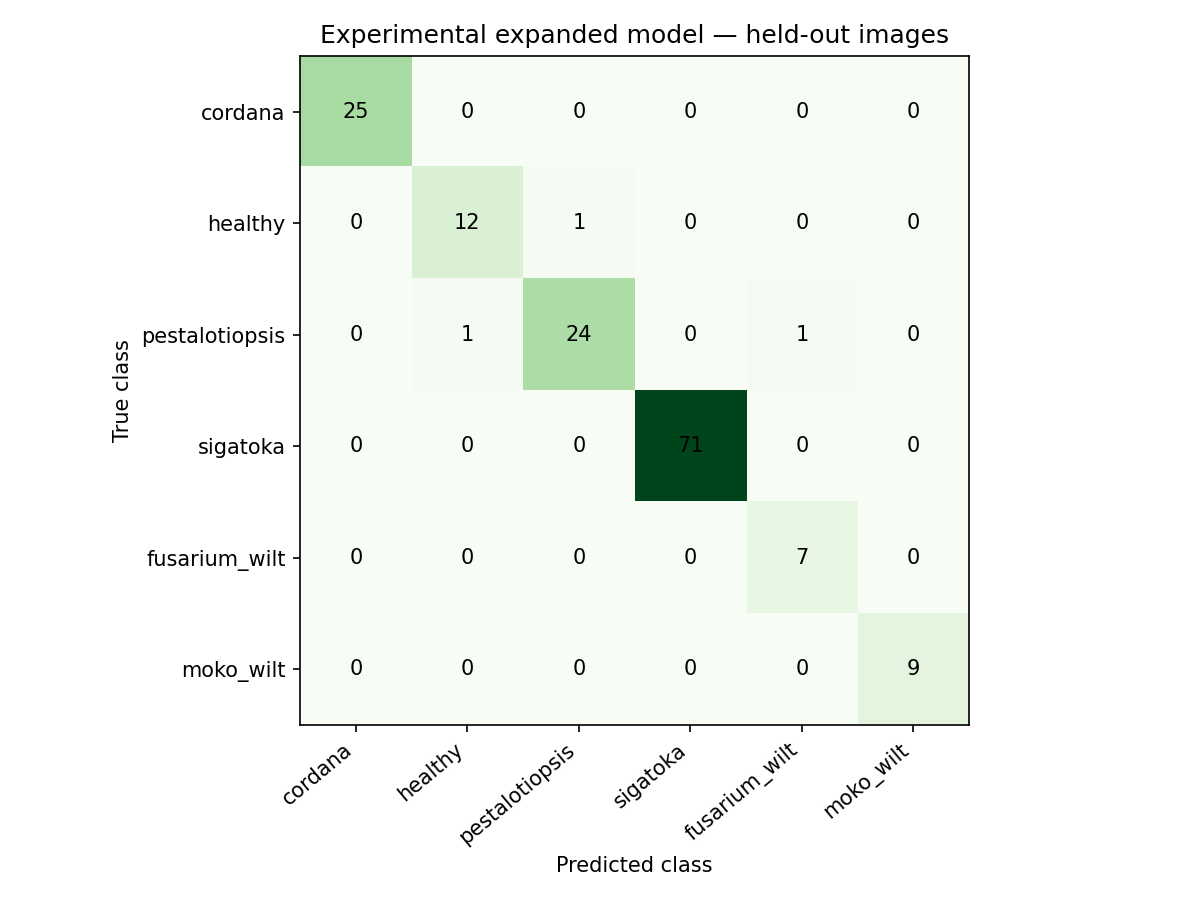

Rows are true classes; columns are predicted classes.


In [6]:
display(DisplayImage(filename=str(folder / "confusion_matrix.png")))
print("Rows are true classes; columns are predicted classes.")


## 5. Reload the real saved model and test a held-out example

In [7]:
import torch
from torch import nn
from torchvision import models, transforms
from PIL import Image
torch.set_num_threads(4)
checkpoint = torch.load(folder / "banana_leaf_expanded_model.pt", map_location="cpu", weights_only=True)
model = models.mobilenet_v3_small(weights=None)
model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(checkpoint["class_names"]))
model.load_state_dict(checkpoint["model_state"])
model.eval()
preprocess = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(), transforms.Normalize(checkpoint["mean"], checkpoint["std"])])
print("Saved classes:", checkpoint["class_names"])


Saved classes: ['cordana', 'healthy', 'pestalotiopsis', 'sigatoka', 'fusarium_wilt', 'moko_wilt']


True dataset label: fusarium_wilt
Predicted label: fusarium_wilt


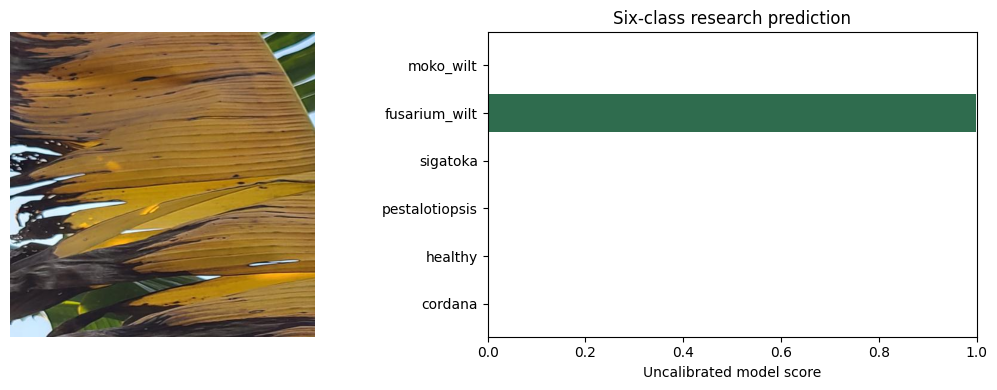

In [8]:
example = manifest[(manifest.split == "test") & (manifest.class_name == "fusarium_wilt")].iloc[0]
with Image.open(example.image) as image:
    photo = image.convert("RGB")
with torch.inference_mode():
    probabilities = model(preprocess(photo).unsqueeze(0)).softmax(1)[0].numpy()
best = int(probabilities.argmax())
print("True dataset label:", example.class_name)
print("Predicted label:", checkpoint["class_names"][best])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(photo); axes[0].axis("off")
axes[1].barh(checkpoint["class_names"], probabilities, color="#2f6c4e")
axes[1].set(xlim=(0,1), xlabel="Uncalibrated model score", title="Six-class research prediction")
fig.tight_layout(); plt.show()


## Interpretation
The dashboard keeps the original four-class model as the default and makes this model an explicit research choice. Neither model confirms a pathogen, Fusarium race, chemical treatment or field diagnosis. Bunchy top and Xanthomonas wilt remain guidance-only. Obtain suitable expert-labeled images and independent farm evaluation before adding those predictions.
